# KKN Radar → pysteps-ready Pseudo-CAPPI 2 km (Data Preparation, Repo 1)

**Notebook นี้คือ "ที่มา" ของข้อมูลใน `data/` ของ repo สาธิต pysteps**
อ่านไฟล์เรดาร์ดิบ UF ของเรดาร์ขอนแก่น (KKN, C-band dual-pol, กรมอุตุนิยมวิทยา) → QC แบบ gentle (ชุดเดียวกับ Level-1 เดิม) → สร้าง **pseudo-CAPPI 2 km** บนกริด Cartesian 1 km รัศมี 240 km → เขียน NetCDF ที่ pysteps ใช้ได้ทันที

| ส่วน | ทำอะไร |
|---|---|
| 0–1 | ติดตั้งแพ็กเกจ, mount Drive, ตั้งค่า (CONFIG) |
| 2 | ฟังก์ชันทั้งหมด (อ่านไฟล์, QC, pseudo-CAPPI, เขียนไฟล์, แผนที่, ภาพ) |
| **BASE** | ทำ 1 volume ทีละขั้น พร้อมภาพตรวจสอบ — ใช้สอนและตรวจความถูกต้อง |
| **BATCH** | ทำทั้งวัน (92 ไฟล์) → รวมเป็นไฟล์รายวันไฟล์เดียว + ภาพ QA + manifest |

**ผลลัพธ์หลัก:** `data/KKN_20240503/KKN_20240503_pcappi2km_dbz.nc` (time, y, x) หน่วย dBZ
- ค่า echo = dBZ, ในรัศมีแต่ไม่มี echo = `zerovalue` (−15 dBZ), นอกรัศมี/ไม่มีไฟล์ = NaN
- attributes ตั้งชื่อตาม metadata ของ pysteps (`xpixelsize`, `projection`, `zerovalue`, ...)

**ข้อจำกัดที่ต้องรู้:** KKN volume นี้มีเพียง 4 มุมยก (0.48–3.39°) pseudo-CAPPI จึงใช้ข้อมูลจริงที่ 2 km ได้ในช่วงประมาณ 32–130 km เท่านั้น ใกล้กว่านั้นใช้ sweep บนสุด ไกลกว่านั้นใช้ sweep ล่างสุด (ความสูงจริงเก็บไว้ในตัวแปร `source_height_m`)

In [1]:
# ================================================================
# CELL 0: Install packages and mount Google Drive
# ================================================================
!pip -q install arm_pyart cmweather cartopy geopandas netCDF4 xarray pyproj

from google.colab import drive
drive.mount("/content/drive")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.8/157.8 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 65.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 61.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the so

## 1. CONFIG
แก้เฉพาะส่วนนี้เมื่อเปลี่ยนวัน/เรดาร์ ทุก path อ้างจาก `ROOT`

In [2]:
# ================================================================
# CELL 1: Imports and configuration
# ================================================================
import os, re, io, bz2, gzip, json, shutil, tempfile, datetime, warnings, traceback
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import requests
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib import animation
from matplotlib.colors import LightSource
from scipy.ndimage import binary_dilation, uniform_filter1d, map_coordinates
from scipy.ndimage import label as cc_label
import geopandas as gpd
from shapely.geometry import box, Point
from shapely.ops import transform as shp_transform
from pyproj import Transformer
import cartopy.crs as ccrs
import cartopy.io.shapereader as cshp
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

warnings.filterwarnings("ignore")
import pyart
try:
    import cmweather  # registers ChaseSpectral, HomeyerRainbow, balance, ...
except Exception:
    pass

PREP_VERSION = "kkn-prep-1.0.0"

# ---------------- paths ----------------
ROOT = Path("/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69")
RADAR_NAME = "KKN"
CASE_DATE = "20240503"            # YYYYMMDD (UTC)
RAW_DATE_FOLDER = "240503"        # YYMMDD folder of raw UF files
RAW_DIR = ROOT / "0data" / "1radar" / RADAR_NAME / RAW_DATE_FOLDER
RAW_PATTERN = f"{RADAR_NAME}240@{CASE_DATE}*.uf.bz2"

OUT_BASE = ROOT / "2output" / "Github_Pysteps_Data_prepare"
REPO_DIR = OUT_BASE / "repo1_kkn_pysteps"                  # mirror of the GitHub repo
DATA_DIR = REPO_DIR / "data" / f"{RADAR_NAME}_{CASE_DATE}"
BASEMAP_DIR = REPO_DIR / "data" / "basemap"
FIG_DIR = REPO_DIR / "figures"
WORK_DIR = OUT_BASE / "_work" / "repo1_pcappi"             # NOT uploaded to GitHub
DAILY_NC = DATA_DIR / f"{RADAR_NAME}_{CASE_DATE}_pcappi2km_dbz.nc"

# ---------------- base (single-volume) run ----------------
SINGLE_TIME = "20240503_1000"     # UTC time tag used in the BASE section

# ---------------- gentle base-QC (same thresholds as Level-1) ----------------
ZH_ECHO_FLOOR_DBZ = 0.0
NONMET_RHOHV_MAX = 0.70
NONMET_ZH_MAX_DBZ = 25.0
SPECKLE_MIN_GATES = 12
FLARE_MIN_LEN_KM = 120.0
FLARE_ZH_MIN_DBZ = 5.0
FLARE_RHOHV_MEAN_MAX = 0.75
FLARE_VELVALID_MAX = 0.30
FLARE_PROTECT_DBZ = 45.0
FLARE_PROTECT_FRAC = 0.03
SW_MAX = 12.0
QC_SD_PHIDP_W = 5
QC_SD_PHIDP_MAX = 20.0

# ---------------- pseudo-CAPPI grid ----------------
PCAPPI_HEIGHT_M = 2000.0          # above radar level
GRID_RES_M = 1000.0
RANGE_MAX_KM = 240.0              # grid half-width and coverage radius
ZEROVALUE_DBZ = -15.0             # inside coverage but no echo
PCAPPI_MIN_DBZ = 0.0              # interpolated values below this -> zerovalue
EFFECTIVE_EARTH_K = 4.0 / 3.0
SLOT_MINUTES = 15
LT_OFFSET_H = 7                   # Thailand local time = UTC+7

# ---------------- figures / cartography ----------------
PUB_MODE = True                   # True: no figure titles (journal captions instead)
SHOW_FIGURES = True
FIG_DPI = 300
MAP_HALF_KM = 255.0               # map frame slightly larger than 240-km coverage
RANGE_RINGS_KM = [60, 120, 180, 240]
RING_LABEL_AZ = 40.0              # azimuth (deg) where ring labels are placed
BOUNDARY_COUNTRIES = ["THA", "LAO", "KHM", "VNM"]
COVERAGE_BG = "#f1f1f1"
WATER_FILL = "#dbe9f4"
WATER_LINE = "#6b8fb3"
TERRAIN_VMAX_M = 1400.0
REFL_LEVELS = np.arange(0, 75, 5)
ZOOM_HALF_KM = None               # e.g. 150 to zoom multi-panel figures on the storm; None = full 255 km
AREA_THRESHOLDS_DBZ = [20, 30, 40, 50]
ECHO_FREQ_DBZ = 20.0
SEQUENCE_TIMES = None             # e.g. ["20240503_0900", ...]; None = auto around peak
MAKE_ANIMATION = True

# ---------------- batch control ----------------
SKIP_EXISTING = True
MAX_VOLUMES = None                # e.g. 3 for a quick test; None = whole day

for d in [DATA_DIR, BASEMAP_DIR, FIG_DIR, WORK_DIR / "pcappi", WORK_DIR / "logs"]:
    d.mkdir(parents=True, exist_ok=True)

print("Py-ART", pyart.__version__, "|", PREP_VERSION)
print("RAW_DIR :", RAW_DIR, "| exists:", RAW_DIR.exists())
print("REPO_DIR:", REPO_DIR)


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

Py-ART 2.3.0 | kkn-prep-1.0.0
RAW_DIR : /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN/240503 | exists: True
REPO_DIR: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo1_kkn_pysteps


## 2. Functions
### 2.1 อ่านไฟล์และ QC พื้นฐาน (ชุดเดียวกับ notebook ของ repo 2)

In [3]:
# ================================================================
# COMMON FUNCTIONS (A): FILE DISCOVERY, RADAR READER, GENTLE BASE-QC
# This block is identical in both data-preparation notebooks
# (repo 1: pysteps, repo 2: Doppler / PyTDA / HID).
# ================================================================

def parse_time_tag(path):
    """KKN240@202405031000.uf.bz2 -> '20240503_1000' (UTC)."""
    m = re.search(rf"{RADAR_NAME}240@(\d{{8}})(\d{{4}})\.uf(\.bz2|\.gz)?$", Path(path).name)
    return f"{m.group(1)}_{m.group(2)}" if m else None


def tag_to_datetime(time_tag):
    return datetime.datetime.strptime(time_tag, "%Y%m%d_%H%M")


def time_label(dt, with_date=True):
    """'03 May 2024 10:00 UTC (17:00 LT)'"""
    lt = dt + datetime.timedelta(hours=LT_OFFSET_H)
    d = dt.strftime("%d %b %Y ") if with_date else ""
    return f"{d}{dt:%H:%M} UTC ({lt:%H:%M} LT)"


def discover_raw_files():
    """Return a DataFrame of raw files found for the case day, sorted by time."""
    rows = []
    for f in sorted(RAW_DIR.glob(RAW_PATTERN)):
        tag = parse_time_tag(f)
        if tag is not None:
            rows.append({"time_tag": tag, "raw_file": str(f),
                         "size_MB": round(f.stat().st_size / 1e6, 2)})
    return pd.DataFrame(rows, columns=["time_tag", "raw_file", "size_MB"])


def expected_slots():
    """Regular UTC time slots for the case day (every SLOT_MINUTES)."""
    t0 = datetime.datetime.strptime(CASE_DATE, "%Y%m%d")
    n = int(24 * 60 / SLOT_MINUTES)
    return [t0 + datetime.timedelta(minutes=SLOT_MINUTES * i) for i in range(n)]


def build_inventory():
    """Compare expected slots with files that exist -> inventory DataFrame."""
    found = discover_raw_files()
    found_map = dict(zip(found["time_tag"], found["raw_file"]))
    rows = []
    for dt in expected_slots():
        tag = dt.strftime("%Y%m%d_%H%M")
        rows.append({"time_tag": tag, "time_utc": dt,
                     "raw_file": found_map.get(tag, ""),
                     "exists": tag in found_map})
    inv = pd.DataFrame(rows)
    off_grid = sorted(set(found_map) - set(inv["time_tag"]))
    if off_grid:
        print("WARNING: files not on the regular time grid (ignored):", off_grid)
    return inv


def read_radar_magic(path, verbose=True):
    """
    Robust KKN reader. Do not trust the extension: TMD '.uf.bz2' files are
    often gzip streams. Detect the compression from the magic bytes.
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with open(path, "rb") as f:
        magic = f.read(4)

    tmp = tempfile.NamedTemporaryFile(suffix=".uf", delete=False)
    tmp_path = tmp.name
    tmp.close()
    try:
        if magic[:3] == b"BZh":
            opener, kind = bz2.open, "bzip2"
        elif magic[:2] == b"\x1f\x8b":
            opener, kind = gzip.open, "gzip"
        else:
            opener, kind = None, "uncompressed"

        if opener is None:
            read_path = str(path)
        else:
            with opener(path, "rb") as fin, open(tmp_path, "wb") as fout:
                shutil.copyfileobj(fin, fout)
            read_path = tmp_path

        try:
            radar = pyart.io.read(read_path)
        except Exception:
            radar = pyart.io.read_uf(read_path)
    finally:
        if os.path.exists(tmp_path):
            os.unlink(tmp_path)

    if verbose:
        print(f"Read {path.name}  [{kind} stream]")
    return radar


def pick_field(radar, candidates):
    for c in candidates:
        if c in radar.fields:
            return c
    return None


def farr(radar, field):
    """Field -> float32 ndarray with NaN for masked gates (None if missing)."""
    if field is None or field not in radar.fields:
        return None
    return np.ma.filled(radar.fields[field]["data"].astype(np.float32), np.nan)


def detect_fields(radar):
    f = {
        "REFL": pick_field(radar, ["corrected_reflectivity", "reflectivity"]),
        "VEL": pick_field(radar, ["velocity"]),
        "SW": pick_field(radar, ["spectrum_width"]),
        "ZDR": pick_field(radar, ["corrected_differential_reflectivity",
                                   "differential_reflectivity"]),
        "PHIDP": pick_field(radar, ["differential_phase"]),
        "RHO": pick_field(radar, ["cross_correlation_ratio"]),
    }
    if f["REFL"] is None:
        raise ValueError(f"No reflectivity field. Available: {list(radar.fields)}")
    return f


def radar_start_time(radar):
    """Volume start time as a plain datetime (Py-ART may return cftime)."""
    t = pyart.util.datetime_from_radar(radar)
    return datetime.datetime(t.year, t.month, t.day, t.hour, t.minute, int(t.second))


def get_nyquist(radar):
    try:
        v = np.asarray(radar.instrument_parameters["nyquist_velocity"]["data"], float)
        v = v[np.isfinite(v) & (v > 0)]
        return float(np.nanmedian(v)) if v.size else np.nan
    except Exception:
        return np.nan


def sweep_index_1d(radar):
    swp = np.zeros(radar.nrays, dtype=np.int16)
    for k in range(radar.nsweeps):
        a = int(radar.sweep_start_ray_index["data"][k])
        b = int(radar.sweep_end_ray_index["data"][k])
        swp[a:b + 1] = k
    return swp


def radar_inventory(radar, fields):
    """Print the facts a radar meteorologist checks first."""
    lat0 = float(radar.latitude["data"][0]); lon0 = float(radar.longitude["data"][0])
    rng = radar.range["data"]
    print(f"  time (volume start) : {radar_start_time(radar):%Y-%m-%d %H:%M:%S} UTC")
    print(f"  location            : {lat0:.4f} N, {lon0:.4f} E, {float(radar.altitude['data'][0]):.0f} m MSL")
    print(f"  sweeps/rays/gates   : {radar.nsweeps} / {radar.nrays} / {radar.ngates}")
    print(f"  elevations (deg)    : {np.round(radar.fixed_angle['data'], 2).tolist()}")
    print(f"  range               : {rng[0]/1e3:.2f}-{rng[-1]/1e3:.1f} km, gate {np.median(np.diff(rng)):.0f} m")
    print(f"  Nyquist velocity    : {get_nyquist(radar):.2f} m/s")
    print(f"  fields used         : {fields}")


# ---------------- gentle base-QC (algorithm kept from Level-1 codebase) ----

def find_flare_rays(radar, zh, rho, vel_finite):
    """Conservative flare-ray (sun spike / interference) detector, per ray."""
    dr_km = float(np.nanmedian(np.diff(radar.range["data"])) / 1000.0)
    min_gate_count = int(FLARE_MIN_LEN_KM / max(dr_km, 0.1))
    valid = np.isfinite(zh) & (zh > FLARE_ZH_MIN_DBZ)
    spike = np.zeros(radar.nrays, dtype=bool)
    for i in range(radar.nrays):
        v = valid[i]
        if v.sum() < min_gate_count:
            continue
        if np.mean(zh[i][v] >= FLARE_PROTECT_DBZ) >= FLARE_PROTECT_FRAC:
            continue                                  # protect real convective cores
        rho_ok = True if rho is None else np.nanmean(rho[i][v]) <= FLARE_RHOHV_MEAN_MAX
        vel_ok = True if vel_finite is None else np.mean(vel_finite[i][v]) <= FLARE_VELVALID_MAX
        spike[i] = rho_ok and vel_ok
    return spike, binary_dilation(spike, iterations=1)


def remove_speckles_polar(mask_keep, radar, min_gates=12, pad=8):
    """Remove connected components < min_gates in each sweep (azimuth wraps)."""
    keep = mask_keep.copy()
    removed = np.zeros_like(keep, dtype=bool)
    swp = sweep_index_1d(radar)
    structure = np.ones((3, 3), dtype=np.int8)
    for k in range(radar.nsweeps):
        ridx = np.where(swp == k)[0]
        if len(ridx) == 0:
            continue
        sub = keep[ridx, :].copy()
        if len(ridx) > 2 * pad:
            padded = np.vstack([sub[-pad:], sub, sub[:pad]])
            lab_p, _ = cc_label(padded, structure=structure)
            sizes = np.bincount(lab_p.ravel())
            lab = lab_p[pad:pad + len(ridx), :]
        else:
            lab, _ = cc_label(sub, structure=structure)
            sizes = np.bincount(lab.ravel())
        small = np.isin(lab, np.where(sizes < min_gates)[0]) & (lab > 0)
        sub[small] = False
        keep[ridx, :] = sub
        removed[ridx, :] = small
    return keep, removed


def circular_sd_deg_range(data_deg, window=5):
    """Circular standard deviation of an angle (PhiDP) along range."""
    x = np.asarray(data_deg, dtype=float)
    valid = np.isfinite(x)
    a = np.deg2rad(np.where(valid, x, 0.0))
    cnt = uniform_filter1d(valid.astype(float), window, axis=1, mode="nearest") * window
    s = uniform_filter1d(np.where(valid, np.sin(a), 0), window, axis=1, mode="nearest") * window
    c = uniform_filter1d(np.where(valid, np.cos(a), 0), window, axis=1, mode="nearest") * window
    with np.errstate(invalid="ignore", divide="ignore"):
        R = np.clip(np.hypot(s / cnt, c / cnt), 1e-6, 1.0)
        sd = np.rad2deg(np.sqrt(-2.0 * np.log(R)))
    sd[cnt < 3] = np.nan
    return sd.astype(np.float32)


# qc_flag bit convention (uint8). A gate keeps reflectivity if (qc_flag & 15) == 0.
QC_BITS = {
    "no_echo_or_below_floor": 1,
    "flare_ray": 2,
    "nonmet_low_rhohv_weak_z": 4,
    "speckle": 8,
    "spectrum_width_invalid": 16,
    "velocity_invalid": 32,
    "phidp_texture_high": 64,
}


def gentle_base_qc(radar, fields, verbose=True):
    """
    Gentle, reflectivity-preserving base-QC.
      keep  = ZH >= floor  AND not flare ray  AND not (low rhoHV & weak ZH)
              AND not a small speckle
    Returns a dict with QC arrays, masks, qc_flag and gate counts.
    """
    zh = farr(radar, fields["REFL"])
    rho = farr(radar, fields["RHO"])
    vel = farr(radar, fields["VEL"])
    sw = farr(radar, fields["SW"])
    phidp = farr(radar, fields["PHIDP"])
    vel_finite = None if vel is None else np.isfinite(vel)

    echo = np.isfinite(zh) & (zh >= ZH_ECHO_FLOOR_DBZ)
    flare_raw, flare_dil = find_flare_rays(radar, zh, rho, vel_finite)
    flare = np.zeros_like(echo)
    flare[flare_dil, :] = True

    if rho is not None:
        nonmet = (echo & ~flare & np.isfinite(rho)
                  & (rho < NONMET_RHOHV_MAX) & (zh < NONMET_ZH_MAX_DBZ))
    else:
        nonmet = np.zeros_like(echo)

    keep, speckle = remove_speckles_polar(echo & ~flare & ~nonmet, radar,
                                          min_gates=SPECKLE_MIN_GATES)

    out = {"zh_raw": zh, "keep": keep,
           "reflectivity_qc": np.where(keep, zh, np.nan).astype(np.float32)}

    flag = np.zeros(zh.shape, dtype=np.uint8)
    flag[~echo] |= QC_BITS["no_echo_or_below_floor"]
    flag[flare] |= QC_BITS["flare_ray"]
    flag[nonmet] |= QC_BITS["nonmet_low_rhohv_weak_z"]
    flag[speckle] |= QC_BITS["speckle"]

    if vel is not None:
        vel_valid = keep & np.isfinite(vel)
        out["velocity_qc"] = np.where(vel_valid, vel, np.nan).astype(np.float32)
        flag[keep & ~vel_valid] |= QC_BITS["velocity_invalid"]
    if sw is not None:
        sw_valid = keep & np.isfinite(sw) & (sw >= 0.0) & (sw <= SW_MAX)
        out["spectrum_width_qc"] = np.where(sw_valid, sw, np.nan).astype(np.float32)
        flag[keep & ~sw_valid] |= QC_BITS["spectrum_width_invalid"]
    if phidp is not None:
        tex = circular_sd_deg_range(phidp, window=QC_SD_PHIDP_W)
        phase_ok = np.isfinite(phidp) & (tex < QC_SD_PHIDP_MAX)
        flag[keep & ~phase_ok] |= QC_BITS["phidp_texture_high"]
    out["qc_flag"] = flag

    n_raw = int(np.isfinite(zh).sum())
    out["counts"] = {
        "raw_finite": n_raw,
        "echo_floor": int(echo.sum()),
        "flare_rays": int(flare_dil.sum()),
        "nonmet_removed": int(nonmet.sum()),
        "speckle_removed": int(speckle.sum()),
        "kept": int(keep.sum()),
        "kept_pct_of_raw": round(100.0 * keep.sum() / max(n_raw, 1), 2),
    }
    if verbose:
        for k, v in out["counts"].items():
            print(f"  {k:<18}: {v}")
    return out

### 2.2 Pseudo-CAPPI 2 km และไฟล์ NetCDF สำหรับ pysteps
หลักการ: ทุกพิกเซลคำนวณระยะบนพื้น (s) และ azimuth → หาความสูงลำคลื่นของทุก sweep ที่ระยะ s (4/3 Earth)
- ถ้ามี sweep อยู่ทั้งใต้และเหนือ 2 km → ประมาณค่าในแนวดิ่ง **ในหน่วย Z เชิงเส้น (mm⁶ m⁻³)**
- ถ้าทุก sweep สูงกว่า 2 km (ไกล) → ใช้ sweep ต่ำสุด; ถ้าทุก sweep ต่ำกว่า 2 km (ใกล้เรดาร์) → ใช้ sweep สูงสุด
- แนวราบใช้ gate ที่ใกล้ที่สุด

In [4]:
# ================================================================
# PSEUDO-CAPPI AND PYSTEPS NETCDF
# ================================================================

def grid_axes():
    h = RANGE_MAX_KM * 1e3
    x = np.arange(-h, h + GRID_RES_M / 2, GRID_RES_M)
    return x, x.copy()                     # y ascending -> pysteps yorigin = "lower"


def beam_height_and_ground_range(rng_m, elev_deg):
    """4/3-Earth beam centre height (above radar) and ground distance."""
    ae = EFFECTIVE_EARTH_K * 6371000.0
    er = np.deg2rad(elev_deg)
    h = np.sqrt(rng_m ** 2 + ae ** 2 + 2 * rng_m * ae * np.sin(er)) - ae
    s = ae * np.arcsin(rng_m * np.cos(er) / (ae + h))
    return h, s


def make_pseudo_cappi(radar, zh_qc, height_m=PCAPPI_HEIGHT_M):
    """
    Pseudo-CAPPI from a QC'd polar volume.
    zh_qc : (nrays, ngates) dBZ with NaN where no echo / removed by QC.
    Returns dict(dbz, source_height_m, coverage, x, y).
    """
    x, y = grid_axes()
    X, Y = np.meshgrid(x, y)
    S = np.hypot(X, Y)
    AZ = np.rad2deg(np.arctan2(X, Y)) % 360.0
    rng = radar.range["data"].astype(float)
    ng = radar.ngates
    dr = float(np.median(np.diff(rng)))
    nsw = radar.nsweeps

    H = np.full((nsw,) + X.shape, np.nan, np.float32)      # beam height at pixel
    ZL = np.full((nsw,) + X.shape, np.nan, np.float32)     # linear Z at pixel
    z_zero = 10.0 ** (ZEROVALUE_DBZ / 10.0)
    for k in range(nsw):
        sl = radar.get_slice(k)
        el = float(np.nanmean(radar.elevation["data"][sl]))
        h_g, s_g = beam_height_and_ground_range(rng, el)
        inside = (S >= s_g[0] - dr / 2) & (S <= s_g[-1] + dr / 2) & (S <= RANGE_MAX_KM * 1e3)
        gidx = np.clip(np.rint(np.interp(S, s_g, np.arange(ng))), 0, ng - 1).astype(int)
        hk = np.interp(S, s_g, h_g)

        az = radar.azimuth["data"][sl].astype(float) % 360.0
        order = np.argsort(az)
        az_s = az[order]
        ext = np.concatenate([az_s - 360.0, az_s, az_s + 360.0])
        idx_ext = np.tile(order, 3)
        j = np.clip(np.searchsorted(ext, AZ), 1, len(ext) - 1)
        jn = np.where(np.abs(ext[j - 1] - AZ) <= np.abs(ext[j] - AZ), j - 1, j)
        daz = np.abs(ext[jn] - AZ)
        ok = daz <= max(1.5 * np.median(np.diff(az_s)), 0.5)
        ray = sl.start + idx_ext[jn]

        cov = inside & ok
        val = zh_qc[ray, gidx]
        lin = np.where(np.isfinite(val), 10.0 ** (val / 10.0), z_zero)
        H[k] = np.where(cov, hk, np.nan)
        ZL[k] = np.where(cov, lin, np.nan)

    below = np.isfinite(H) & (H <= height_m)
    above = np.isfinite(H) & (H > height_m)
    has_lo, has_hi = below.any(0), above.any(0)
    k_lo = np.where(has_lo, nsw - 1 - np.argmax(below[::-1], axis=0), 0)
    k_hi = np.where(has_hi, np.argmax(above, axis=0), 0)
    take = lambda A, k: np.take_along_axis(A, k[None], axis=0)[0]
    h_lo, h_hi = take(H, k_lo), take(H, k_hi)
    z_lo, z_hi = take(ZL, k_lo), take(ZL, k_hi)

    w = np.clip((height_m - h_lo) / np.where(h_hi > h_lo, h_hi - h_lo, 1.0), 0, 1)
    zlin = np.full(X.shape, np.nan, np.float32)
    src_h = np.full(X.shape, np.nan, np.float32)
    both = has_lo & has_hi
    zlin[both] = (1 - w[both]) * z_lo[both] + w[both] * z_hi[both]
    src_h[both] = height_m
    only_lo = has_lo & ~has_hi            # near radar: all beams below target
    zlin[only_lo], src_h[only_lo] = z_lo[only_lo], h_lo[only_lo]
    only_hi = has_hi & ~has_lo            # far range: all beams above target
    zlin[only_hi], src_h[only_hi] = z_hi[only_hi], h_hi[only_hi]

    coverage = np.isfinite(zlin)
    with np.errstate(divide="ignore", invalid="ignore"):
        dbz = 10.0 * np.log10(zlin)
    dbz[coverage & (dbz < PCAPPI_MIN_DBZ)] = ZEROVALUE_DBZ
    return {"dbz": dbz.astype(np.float32), "source_height_m": src_h,
            "coverage": coverage, "x": x, "y": y}


def pysteps_attrs(lon0, lat0, x, y):
    """Global attributes named after pysteps metadata keys."""
    return {
        "projection": aeqd_proj4(lon0, lat0),
        "x1": float(x[0] - GRID_RES_M / 2), "x2": float(x[-1] + GRID_RES_M / 2),
        "y1": float(y[0] - GRID_RES_M / 2), "y2": float(y[-1] + GRID_RES_M / 2),
        "xpixelsize": float(GRID_RES_M), "ypixelsize": float(GRID_RES_M),
        "cartesian_unit": "m", "yorigin": "lower",
        "unit": "dBZ", "transform": "dB", "accutime": float(SLOT_MINUTES),
        "timestep": float(SLOT_MINUTES), "threshold": float(PCAPPI_MIN_DBZ),
        "zerovalue": float(ZEROVALUE_DBZ), "institution": "Thai Meteorological Department (radar data)",
    }


def make_dataset(dbz_stack, times, available, pc, radar_info, scan_times=None):
    """Build the CF/pysteps NetCDF dataset (one or many times)."""
    x, y = pc["x"], pc["y"]
    lon0, lat0, alt0 = radar_info["lon"], radar_info["lat"], radar_info["alt"]
    tr = Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326", always_xy=True)
    LON, LAT = tr.transform(*np.meshgrid(x, y))
    ds = xr.Dataset(
        {
            "reflectivity": (("time", "y", "x"), dbz_stack.astype(np.float32)),
            "source_height_m": (("y", "x"), pc["source_height_m"].astype(np.float32)),
            "coverage_mask": (("y", "x"), pc["coverage"].astype(np.uint8)),
            "time_available": (("time",), np.asarray(available, np.uint8)),
            "lon": (("y", "x"), LON.astype(np.float32)),
            "lat": (("y", "x"), LAT.astype(np.float32)),
            "crs": ((), np.int32(0)),
        },
        coords={"time": pd.to_datetime(times), "x": x.astype(np.float32),
                "y": y.astype(np.float32)},
    )
    if scan_times is not None:
        ds["volume_start_time"] = (("time",), pd.to_datetime(scan_times))
    ds["reflectivity"].attrs = {
        "long_name": f"pseudo-CAPPI {PCAPPI_HEIGHT_M/1000:.1f} km equivalent reflectivity factor (gentle base-QC)",
        "standard_name": "equivalent_reflectivity_factor", "units": "dBZ",
        "grid_mapping": "crs", "coordinates": "lon lat",
        "comment": f"{ZEROVALUE_DBZ} dBZ = inside radar coverage but no echo; NaN = outside coverage or missing volume",
    }
    ds["source_height_m"].attrs = {"long_name": "height above radar of the data used at each pixel",
                                   "units": "m", "grid_mapping": "crs"}
    ds["coverage_mask"].attrs = {"long_name": "radar coverage (1 = covered)", "units": "1",
                                 "grid_mapping": "crs"}
    ds["time_available"].attrs = {"long_name": "1 = radar volume available for this slot", "units": "1"}
    ds["x"].attrs = {"standard_name": "projection_x_coordinate", "units": "m"}
    ds["y"].attrs = {"standard_name": "projection_y_coordinate", "units": "m"}
    ds["lon"].attrs = {"standard_name": "longitude", "units": "degrees_east"}
    ds["lat"].attrs = {"standard_name": "latitude", "units": "degrees_north"}
    ds["crs"].attrs = {"grid_mapping_name": "azimuthal_equidistant",
                       "longitude_of_projection_origin": lon0,
                       "latitude_of_projection_origin": lat0,
                       "false_easting": 0.0, "false_northing": 0.0,
                       "crs_wkt": Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326").source_crs.to_wkt()}
    ds.attrs = {
        "title": f"{RADAR_NAME} pseudo-CAPPI {PCAPPI_HEIGHT_M/1000:.1f} km reflectivity for pysteps",
        "Conventions": "CF-1.8",
        "radar": RADAR_NAME, "radar_latitude": lat0, "radar_longitude": lon0,
        "radar_altitude_m": alt0,
        "pcappi_height_m_above_radar": PCAPPI_HEIGHT_M,
        "method": ("pseudo-CAPPI: vertical interpolation in linear Z between the sweeps "
                   "bracketing the target height; lowest sweep beyond, highest sweep inside; "
                   "nearest gate horizontally; 4/3 effective Earth radius"),
        "qc": (f"gentle base-QC: ZH>={ZH_ECHO_FLOOR_DBZ} dBZ, flare-ray removal, "
               f"non-met removal (rhoHV<{NONMET_RHOHV_MAX} & ZH<{NONMET_ZH_MAX_DBZ} dBZ), "
               f"speckle <{SPECKLE_MIN_GATES} gates"),
        "time_convention": "UTC; slot time = raw file name time",
        "source": "TMD KKN UF volumes", "processing_code": PREP_VERSION,
        "history": f"created {datetime.datetime.utcnow():%Y-%m-%dT%H:%M:%SZ}",
        **pysteps_attrs(lon0, lat0, x, y),
    }
    return ds


def write_pcappi_nc(ds, path):
    enc = {
        "reflectivity": {"dtype": "int16", "scale_factor": 0.1, "add_offset": 0.0,
                         "_FillValue": np.int16(-32768), "zlib": True, "complevel": 5,
                         "shuffle": True, "chunksizes": (1, ds.sizes["y"], ds.sizes["x"])},
        "source_height_m": {"dtype": "int16", "scale_factor": 1.0, "_FillValue": np.int16(-32768),
                            "zlib": True, "complevel": 5},
        "coverage_mask": {"zlib": True, "complevel": 5},
        "lon": {"zlib": True, "complevel": 5, "least_significant_digit": 4},
        "lat": {"zlib": True, "complevel": 5, "least_significant_digit": 4},
        "time": {"units": "minutes since 1970-01-01 00:00:00", "dtype": "int64"},
    }
    if "volume_start_time" in ds:
        enc["volume_start_time"] = {"units": "seconds since 1970-01-01 00:00:00", "dtype": "float64"}
    tmp = Path(str(path) + ".tmp")
    ds.to_netcdf(tmp, encoding=enc, engine="netcdf4")
    os.replace(tmp, path)
    return path


def load_pcappi_for_pysteps(path, start=None, end=None):
    """
    Read the NetCDF and return (R, metadata, timestamps) in the form pysteps uses:
      R: (t, y, x) dBZ, metadata: dict with pysteps keys.
    """
    ds = xr.open_dataset(path)
    if start or end:
        ds = ds.sel(time=slice(start, end))
    R = ds["reflectivity"].values.astype(float)
    keys = ["projection", "x1", "x2", "y1", "y2", "xpixelsize", "ypixelsize",
            "cartesian_unit", "yorigin", "unit", "transform", "accutime", "timestep",
            "threshold", "zerovalue", "institution"]
    meta = {k: ds.attrs[k] for k in keys if k in ds.attrs}
    meta["timestamps"] = pd.to_datetime(ds["time"].values).to_pydatetime()
    return R, meta, meta["timestamps"]


def echo_stats(dbz):
    """Area (km^2) above thresholds and max dBZ for one pseudo-CAPPI."""
    px_km2 = (GRID_RES_M / 1000.0) ** 2
    out = {f"area_ge{t}_km2": float(np.nansum(dbz >= t) * px_km2) for t in AREA_THRESHOLDS_DBZ}
    out["max_dbz"] = float(np.nanmax(dbz)) if np.isfinite(dbz).any() else np.nan
    return out

### 2.3 รูปแบบภาพ แผนที่ และขอบเขตการปกครอง (ชุดเดียวกับ notebook ของ repo 2)
- เส้นโครงแผนที่ **Azimuthal Equidistant ที่มีเรดาร์เป็นศูนย์กลาง** → วงระยะ 60/120/180/240 km เป็นวงกลมจริง
- ขอบเขตจังหวัด/อำเภอ: **geoBoundaries (CC BY 4.0)** ดาวน์โหลดครั้งแรก แล้วเก็บไฟล์เล็กใน `data/basemap/`
- ภูมิประเทศ: AWS Terrain Tiles (SRTM/GMTED composite) สำหรับ hillshade ใน Fig. 1

In [5]:
# ================================================================
# COMMON FUNCTIONS (B): PUBLICATION STYLE, BASEMAP DATA, MAP DRAWING
# This block is identical in both data-preparation notebooks.
# ================================================================

MM = 1 / 25.4                     # inch per mm
FIG_W_SINGLE = 85 * MM            # journal single column
FIG_W_ONEHALF = 140 * MM
FIG_W_DOUBLE = 174 * MM           # journal double column


def set_pub_style():
    sans = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": sans,
        "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
        "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
        "axes.linewidth": 0.6, "lines.linewidth": 0.9,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.direction": "out", "ytick.direction": "out",
        "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42, "ps.fonttype": 42,       # embed TrueType (journal requirement)
        "figure.dpi": 110,
    })


def save_figure(fig, name):
    """Save PDF (vector text, rasterized data) + PNG 300 dpi into FIG_DIR."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    out = []
    for ext in ("pdf", "png"):
        p = FIG_DIR / f"{name}.{ext}"
        fig.savefig(p, dpi=FIG_DPI)
        out.append(p)
    print("Saved:", ", ".join(f"{p.name} ({p.stat().st_size/1e6:.2f} MB)" for p in out))
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    return out


def get_cmap_safe(names, fallback="turbo"):
    for n in ([names] if isinstance(names, str) else names):
        try:
            return mpl.colormaps[n]
        except Exception:
            continue
    return mpl.colormaps[fallback]


def discrete_cmap_norm(names, levels, design_range=None, extend="max", fallback="turbo"):
    """Sample a (continuous) colormap into len(levels)-1 discrete colours."""
    base = get_cmap_safe(names, fallback)
    lo, hi = design_range if design_range else (levels[0], levels[-1])
    pos = (np.asarray(levels[:-1]) + np.diff(levels) / 2 - lo) / (hi - lo)
    cmap = mcolors.ListedColormap(base(np.clip(pos, 0, 1)))
    if extend in ("max", "both"):
        cmap.set_over(base(min(1.0, (levels[-1] + np.diff(levels)[-1] - lo) / (hi - lo))))
    if extend in ("min", "both"):
        cmap.set_under(base(max(0.0, (levels[0] - np.diff(levels)[0] - lo) / (hi - lo))))
    cmap.set_bad((0, 0, 0, 0))
    return cmap, mcolors.BoundaryNorm(levels, cmap.N)


def refl_cmap_norm():
    # ChaseSpectral / HomeyerRainbow are colour-vision-deficiency friendly
    # radar scales (designed over about -10..80 dBZ); 5-dBZ classes from 0 dBZ.
    return discrete_cmap_norm(["ChaseSpectral", "HomeyerRainbow", "pyart_HomeyerRainbow"],
                              REFL_LEVELS, design_range=(-10, 80))


# ---------------- map projection ----------------

def map_projection(lon0, lat0):
    """Azimuthal equidistant centred on the radar: range rings are true circles."""
    return ccrs.AzimuthalEquidistant(central_longitude=lon0, central_latitude=lat0)


def aeqd_proj4(lon0, lat0):
    return (f"+proj=aeqd +lat_0={lat0:.6f} +lon_0={lon0:.6f} +x_0=0 +y_0=0 "
            f"+datum=WGS84 +units=m +no_defs")


def domain_lonlat_bbox(lon0, lat0, half_km):
    tr = Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326", always_xy=True)
    t = np.linspace(-1, 1, 41) * half_km * 1e3
    xx = np.concatenate([t, t, np.full_like(t, t[0]), np.full_like(t, t[-1])])
    yy = np.concatenate([np.full_like(t, t[0]), np.full_like(t, t[-1]), t, t])
    lon, lat = tr.transform(xx, yy)
    return float(lon.min()), float(lat.min()), float(lon.max()), float(lat.max())


# ---------------- administrative boundaries (geoBoundaries, CC BY 4.0) ----

def _download_geoboundaries(iso, adm):
    """Download a simplified geoBoundaries layer (gbOpen, CC BY 4.0)."""
    urls = []
    try:
        meta = requests.get(f"https://www.geoboundaries.org/api/current/gbOpen/{iso}/{adm}/",
                            timeout=60).json()
        for key in ("simplifiedGeometryGeoJSON", "gjDownloadURL"):
            if meta.get(key):
                urls.append(meta[key])
    except Exception as e:
        print(f"  geoBoundaries API not reachable for {iso} {adm}: {e}")
    urls.append("https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/"
                f"gbOpen/{iso}/{adm}/geoBoundaries-{iso}-{adm}_simplified.geojson")
    for u in urls:
        try:
            r = requests.get(u, timeout=180)
            r.raise_for_status()
            return gpd.read_file(io.BytesIO(r.content))
        except Exception as e:
            print(f"  failed: {u} ({e})")
    return None


def clean_admin_name(name):
    name = str(name)
    for s in [" Province", " province", " Changwat", "Changwat ", " Prefecture"]:
        name = name.replace(s, "")
    return name.strip()


def prepare_boundaries(lon0, lat0):
    """
    Province (ADM1) and district (ADM2, Thailand) boundaries clipped to the
    radar domain. Read from data/basemap if present; otherwise download once
    from geoBoundaries and save a small GeoPackage there (for GitHub).
    """
    gpkg = BASEMAP_DIR / f"boundaries_{RADAR_NAME}_{int(MAP_HALF_KM)}km.gpkg"
    layers = {}
    if gpkg.exists():
        for lyr in ("adm0", "adm1", "adm2"):
            try:
                layers[lyr] = gpd.read_file(gpkg, layer=lyr)
            except Exception:
                layers[lyr] = None
        print("Boundaries read from", gpkg.name)
        return layers

    BASEMAP_DIR.mkdir(parents=True, exist_ok=True)
    bbox = box(*domain_lonlat_bbox(lon0, lat0, MAP_HALF_KM + 40))
    plan = {"adm0": [(c, "ADM0") for c in BOUNDARY_COUNTRIES],
            "adm1": [(c, "ADM1") for c in BOUNDARY_COUNTRIES if c != "VNM"],
            "adm2": [("THA", "ADM2")]}
    for lyr, items in plan.items():
        parts = []
        for iso, adm in items:
            print(f"Downloading geoBoundaries {iso} {adm} ...")
            g = _download_geoboundaries(iso, adm)
            if g is None:
                continue
            g = g.to_crs("EPSG:4326")
            g = g[g.intersects(bbox)].copy()
            g["geometry"] = g.geometry.intersection(bbox)
            g["iso"] = iso
            g["name"] = g["shapeName"].map(clean_admin_name) if "shapeName" in g else ""
            parts.append(g[["iso", "name", "geometry"]])
        layers[lyr] = (gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs="EPSG:4326")
                       if parts else None)
        if layers[lyr] is not None and len(layers[lyr]):
            layers[lyr].to_file(gpkg, layer=lyr, driver="GPKG")
    if gpkg.exists():
        print(f"Saved {gpkg.name} ({gpkg.stat().st_size/1e6:.2f} MB)")
    else:
        print("WARNING: boundaries unavailable; maps will be drawn without them.")
    return layers


# ---------------- terrain (AWS Terrain Tiles, Terrarium encoding) ----------

def _lonlat_to_tile_xy(lon, lat, z):
    n = 2 ** z
    x = (np.asarray(lon) + 180.0) / 360.0 * n
    lat_r = np.deg2rad(np.asarray(lat))
    y = (1.0 - np.arcsinh(np.tan(lat_r)) / np.pi) / 2.0 * n
    return x, y


def prepare_terrain(lon0, lat0, res_m=600.0, zoom=8):
    """
    Terrain on the radar-centred AEQD grid (for the Fig. 1 hillshade).
    Source: AWS Open Data 'Terrain Tiles' (Mapzen; SRTM/GMTED/ETOPO composite).
    Cached as a small NetCDF in data/basemap.
    """
    nc = BASEMAP_DIR / f"terrain_{RADAR_NAME}_aeqd_{int(res_m)}m.nc"
    if nc.exists():
        ds = xr.open_dataset(nc)
        print("Terrain read from", nc.name)
        return ds["x"].values, ds["y"].values, ds["elevation"].values.astype(np.float32)

    half = (MAP_HALF_KM + 5) * 1e3
    x = np.arange(-half, half + res_m, res_m)
    y = np.arange(-half, half + res_m, res_m)
    X, Y = np.meshgrid(x, y)
    tr = Transformer.from_crs(aeqd_proj4(lon0, lat0), "EPSG:4326", always_xy=True)
    LON, LAT = tr.transform(X, Y)
    tx, ty = _lonlat_to_tile_xy(LON, LAT, zoom)
    x0, x1 = int(np.floor(tx.min())), int(np.floor(tx.max()))
    y0, y1 = int(np.floor(ty.min())), int(np.floor(ty.max()))
    print(f"Downloading {(x1-x0+1)*(y1-y0+1)} terrain tiles (zoom {zoom}) ...")
    mosaic = np.full(((y1 - y0 + 1) * 256, (x1 - x0 + 1) * 256), np.nan, np.float32)
    for ix in range(x0, x1 + 1):
        for iy in range(y0, y1 + 1):
            url = f"https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{zoom}/{ix}/{iy}.png"
            try:
                r = requests.get(url, timeout=60)
                r.raise_for_status()
                rgb = np.asarray(Image.open(io.BytesIO(r.content)).convert("RGB"), np.float32)
                elev = rgb[..., 0] * 256 + rgb[..., 1] + rgb[..., 2] / 256 - 32768
                mosaic[(iy - y0) * 256:(iy - y0 + 1) * 256,
                       (ix - x0) * 256:(ix - x0 + 1) * 256] = elev
            except Exception as e:
                print(f"  tile {zoom}/{ix}/{iy} failed: {e}")
    if np.all(np.isnan(mosaic)):
        print("WARNING: terrain unavailable; Fig. 1 will be drawn without hillshade.")
        return None
    py = (ty - y0) * 256 - 0.5
    px = (tx - x0) * 256 - 0.5
    elev = map_coordinates(np.nan_to_num(mosaic, nan=0.0), [py, px], order=1).astype(np.float32)
    elev = np.clip(elev, -50, None)

    BASEMAP_DIR.mkdir(parents=True, exist_ok=True)
    ds = xr.Dataset({"elevation": (("y", "x"), elev)}, coords={"x": x, "y": y})
    ds["elevation"].attrs = {"units": "m", "long_name": "terrain elevation above MSL"}
    ds.attrs = {"projection": aeqd_proj4(lon0, lat0),
                "source": "AWS Open Data Terrain Tiles (Mapzen terrarium); "
                          "SRTM, GMTED2010, ETOPO1 composite"}
    ds.to_netcdf(nc, encoding={"elevation": {"dtype": "int16", "zlib": True, "complevel": 5}})
    print(f"Saved {nc.name} ({nc.stat().st_size/1e6:.2f} MB)")
    return x, y, elev


# ---------------- natural features (Natural Earth via cartopy) ----------------

def ne_feature(category, name, scale="10m"):
    try:
        return list(cshp.Reader(cshp.natural_earth(scale, category, name)).geometries())
    except Exception as e:
        print(f"  Natural Earth {name} unavailable ({e})")
        return []


def prepare_layers(lon0, lat0):
    """Everything the maps need, projected once to the radar AEQD system."""
    proj4 = aeqd_proj4(lon0, lat0)
    adm = prepare_boundaries(lon0, lat0)
    L = {"lon0": lon0, "lat0": lat0, "proj": map_projection(lon0, lat0)}
    for k in ("adm0", "adm1", "adm2"):
        g = adm.get(k)
        L[k] = g.to_crs(proj4) if g is not None and len(g) else None
        if L[k] is not None:
            # simplify for drawing (metres): smaller PDFs, faster plots, no visible change
            tol = {"adm0": 100.0, "adm1": 150.0, "adm2": 250.0}[k]
            L[k]["geometry"] = L[k].geometry.simplify(tol, preserve_topology=True)

    clip = box(*domain_lonlat_bbox(lon0, lat0, MAP_HALF_KM + 40))
    tr = Transformer.from_crs("EPSG:4326", proj4, always_xy=True)
    for key, cat, name in [("rivers", "physical", "rivers_lake_centerlines"),
                           ("lakes", "physical", "lakes")]:
        geoms = [g.intersection(clip) for g in ne_feature(cat, name) if g.intersects(clip)]
        L[key] = [shp_transform(tr.transform, g) for g in geoms if not g.is_empty]
    return L


# ---------------- map drawing ----------------

def halo(width=1.6, color="white"):
    return [pe.withStroke(linewidth=width, foreground=color)]


def range_ring_xy(r_km, n=361):
    t = np.linspace(0, 2 * np.pi, n)
    return r_km * 1e3 * np.sin(t), r_km * 1e3 * np.cos(t)


def setup_map_axes(ax, L, half_km=None):
    half_km = half_km or MAP_HALF_KM
    ax._kkn_half_km = half_km
    h = half_km * 1e3
    ax.set_extent([-h, h, -h, h], crs=L["proj"])
    ax.set_facecolor("white")
    ax.spines["geo"].set_linewidth(0.6)


def draw_coverage_background(ax, L, color=COVERAGE_BG):
    """Light grey inside radar coverage: separates 'no echo' from 'no data'."""
    x, y = range_ring_xy(RANGE_MAX_KM)
    ax.fill(x, y, color=color, transform=L["proj"], zorder=0.5, lw=0)


def draw_boundaries(ax, L, districts=True):
    P = L["proj"]
    if districts and L.get("adm2") is not None:
        ax.add_geometries(L["adm2"].geometry, crs=P, facecolor="none",
                          edgecolor="0.55", linewidth=0.22, alpha=0.7, zorder=3.0)
    for g in L.get("lakes", []):
        ax.add_geometries([g], crs=P, facecolor=WATER_FILL, edgecolor=WATER_LINE,
                          linewidth=0.3, zorder=3.1)
    for g in L.get("rivers", []):
        ax.add_geometries([g], crs=P, facecolor="none", edgecolor=WATER_LINE,
                          linewidth=0.45, zorder=3.1)
    if L.get("adm1") is not None:
        ax.add_geometries(L["adm1"].geometry, crs=P, facecolor="none",
                          edgecolor="0.25", linewidth=0.55, zorder=3.2)
    if L.get("adm0") is not None:
        ax.add_geometries(L["adm0"].geometry, crs=P, facecolor="none",
                          edgecolor="white", linewidth=2.0, zorder=3.3)
        ax.add_geometries(L["adm0"].geometry, crs=P, facecolor="none",
                          edgecolor="black", linewidth=0.9, zorder=3.4)


def draw_rings(ax, L, label=True):
    P = L["proj"]
    for r in RANGE_RINGS_KM:
        x, y = range_ring_xy(r)
        last = r == max(RANGE_RINGS_KM)
        ax.plot(x, y, transform=P, color="0.15", lw=0.7 if last else 0.45,
                ls="-" if last else (0, (3, 2)), alpha=0.9, zorder=4)
        if label and r <= getattr(ax, "_kkn_half_km", MAP_HALF_KM):
            a = np.deg2rad(RING_LABEL_AZ)
            ax.text(r * 1e3 * np.sin(a), r * 1e3 * np.cos(a), f"{r} km", transform=P,
                    fontsize=5.5, color="0.1", ha="center", va="center", rotation=0,
                    path_effects=halo(1.5), zorder=6)


def draw_radar_marker(ax, L, label=True):
    P = L["proj"]
    ax.plot(0, 0, marker="^", ms=5.5, mfc="black", mec="white", mew=0.7,
            transform=P, zorder=7)
    if label:
        ax.text(6e3, -9e3, RADAR_NAME, transform=P, fontsize=6.5, fontweight="bold",
                ha="left", va="top", path_effects=halo(1.8), zorder=7)


def draw_province_labels(ax, L, fontsize=5.8, min_sep_km=28):
    if L.get("adm1") is None:
        return
    g = L["adm1"]
    placed = []
    th = g[g["iso"] == "THA"].copy()
    th["area"] = th.geometry.area
    for _, row in th.sort_values("area", ascending=False).iterrows():
        p = row.geometry.representative_point()
        if np.hypot(p.x, p.y) > (RANGE_MAX_KM - 8) * 1e3 or row["area"] < 8e8:
            continue
        if any(np.hypot(p.x - q[0], p.y - q[1]) < min_sep_km * 1e3 for q in placed):
            continue
        ax.text(p.x, p.y, row["name"], transform=L["proj"], fontsize=fontsize,
                color="0.15", ha="center", va="center", path_effects=halo(1.6), zorder=6)
        placed.append((p.x, p.y))


def draw_country_labels(ax, L):
    if L.get("adm0") is None:
        return
    names = {"LAO": "L A O   P D R", "KHM": "C A M B O D I A", "VNM": "V I E T   N A M"}
    for iso, txt in names.items():
        sub = L["adm0"][L["adm0"]["iso"] == iso]
        if not len(sub):
            continue
        geom = sub.geometry.union_all() if hasattr(sub.geometry, "union_all") else sub.unary_union
        geom = geom.intersection(Point(0, 0).buffer((RANGE_MAX_KM - 15) * 1e3))
        if geom.is_empty or geom.area < 2e9:
            continue
        p = geom.representative_point()
        ax.text(p.x, p.y, txt, transform=L["proj"], fontsize=6, style="italic",
                color="0.35", ha="center", va="center", path_effects=halo(1.6), zorder=6)


def draw_gridlines(ax, left=True, bottom=True):
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.3,
                      color="0.45", alpha=0.45, linestyle=":", x_inline=False,
                      y_inline=False, rotate_labels=False, zorder=4.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left
    gl.bottom_labels = bottom
    gl.xlocator = mticker.FixedLocator(np.arange(90, 115, 1))
    gl.ylocator = mticker.FixedLocator(np.arange(5, 30, 1))
    gl.xformatter = LongitudeFormatter(number_format=".0f")
    gl.yformatter = LatitudeFormatter(number_format=".0f")
    gl.xlabel_style = {"size": 6}
    gl.ylabel_style = {"size": 6}
    return gl


def draw_scale_bar(ax, L, length_km=100):
    """Alternating black/white scale bar in the lower-left corner (outside coverage)."""
    P = L["proj"]
    hk = getattr(ax, "_kkn_half_km", MAP_HALF_KM)
    h, f = hk * 1e3, hk / MAP_HALF_KM            # f scales offsets when zoomed
    if hk < 200:
        length_km = 50
    x0, y0, hgt = -h + 12e3 * f, -h + 14e3 * f, 4e3 * f
    seg = length_km * 1e3 / 2
    ax.add_patch(mpatches.Rectangle((x0 - 5e3 * f, y0 - 4e3 * f), 2 * seg + 22e3 * f, hgt + 15e3 * f,
                                    transform=P, facecolor="white", edgecolor="none",
                                    alpha=0.85, zorder=7.9))
    for i in range(2):
        ax.add_patch(mpatches.Rectangle((x0 + i * seg, y0), seg, hgt, transform=P,
                                        facecolor="black" if i == 0 else "white",
                                        edgecolor="black", lw=0.5, zorder=8))
    for i, v in enumerate([0, length_km // 2, length_km]):
        ax.text(x0 + i * seg, y0 + hgt + 2.5e3 * f, f"{v}", transform=P, fontsize=5.5,
                ha="center", va="bottom", zorder=8, path_effects=halo(1.2))
    ax.text(x0 + 2 * seg + 5e3 * f, y0 + hgt / 2, "km", transform=P, fontsize=5.5,
            ha="left", va="center", zorder=8, path_effects=halo(1.2))


def draw_north_arrow(ax, L):
    P = L["proj"]
    hk = getattr(ax, "_kkn_half_km", MAP_HALF_KM)
    h, f = hk * 1e3, hk / MAP_HALF_KM
    x, y = h - 18e3 * f, -h + 14e3 * f
    ax.annotate("", xy=(x, y + 26e3 * f), xytext=(x, y), xycoords=P._as_mpl_transform(ax),
                arrowprops=dict(arrowstyle="-|>,head_width=0.25,head_length=0.5",
                                lw=0.8, color="black"), zorder=8)
    ax.text(x, y + 29e3 * f, "N", transform=P, fontsize=6.5, fontweight="bold",
            ha="center", va="bottom", zorder=8, path_effects=halo(1.2))


def panel_label(ax, letter):
    ax.text(0.015, 0.985, f"({letter})", transform=ax.transAxes, fontsize=8,
            fontweight="bold", ha="left", va="top", zorder=10,
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85))


def corner_text(ax, txt, loc="upper right", fontsize=6):
    xy = {"upper right": (0.985, 0.985, "right", "top"),
          "lower right": (0.985, 0.015, "right", "bottom"),
          "upper left": (0.015, 0.985, "left", "top")}[loc]
    ax.text(xy[0], xy[1], txt, transform=ax.transAxes, fontsize=fontsize,
            ha=xy[2], va=xy[3], zorder=10,
            bbox=dict(boxstyle="square,pad=0.2", fc="white", ec="none", alpha=0.85))


def decorate_map(ax, L, letter=None, provinces=False, districts=True, rings=True,
                 grid_left=True, grid_bottom=True, scalebar=True, north=True,
                 countries=True, coverage_bg=True, half_km=None):
    setup_map_axes(ax, L, half_km)
    if coverage_bg:
        draw_coverage_background(ax, L)
    draw_boundaries(ax, L, districts=districts)
    if rings:
        draw_rings(ax, L)
    draw_radar_marker(ax, L)
    if provinces:
        draw_province_labels(ax, L)
    if countries:
        draw_country_labels(ax, L)
    draw_gridlines(ax, left=grid_left, bottom=grid_bottom)
    if scalebar:
        draw_scale_bar(ax, L)
    if north:
        draw_north_arrow(ax, L)
    if letter:
        panel_label(ax, letter)


def plot_ppi_on_map(ax, radar, data, sweep, L, cmap, norm):
    """Polar sweep drawn with gate edges in radar-centred AEQD metres."""
    x, y, _ = radar.get_gate_x_y_z(sweep, edges=True)
    sl = radar.get_slice(sweep)
    return ax.pcolormesh(x, y, np.ma.masked_invalid(data[sl]), cmap=cmap, norm=norm,
                         transform=L["proj"], rasterized=True, zorder=2, shading="flat")


def add_colorbar(fig, mappable, axes, label, orientation="horizontal", extend="max",
                 ticks=None, **kw):
    kw.setdefault("shrink", 0.7 if orientation == "horizontal" else 0.85)
    kw.setdefault("aspect", 40 if orientation == "horizontal" else 28)
    kw.setdefault("pad", 0.04 if orientation == "horizontal" else 0.02)
    cb = fig.colorbar(mappable, ax=axes, orientation=orientation, extend=extend,
                      ticks=ticks, **kw)
    cb.set_label(label, fontsize=7)
    cb.ax.tick_params(labelsize=6, width=0.5, length=2)
    cb.outline.set_linewidth(0.5)
    return cb


def plot_study_area(L, terrain, name="Fig01_study_area"):
    """Fig. 1: hillshaded terrain, boundaries, 60-km rings, Thailand locator inset."""
    fig = plt.figure(figsize=(FIG_W_ONEHALF, FIG_W_ONEHALF * 0.80))
    ax = fig.add_axes([0.0, 0.0, 0.78, 1.0], projection=L["proj"])
    setup_map_axes(ax, L)

    if terrain is not None:
        tx, ty, elev = terrain
        hyp = mcolors.LinearSegmentedColormap.from_list("hypso_muted", [
            (0.00, "#e9efe0"), (0.10, "#d6e3c3"), (0.22, "#c9d8a8"),
            (0.40, "#e2d6a8"), (0.62, "#cdb48d"), (0.82, "#a98c74"), (1.00, "#8a7a70")])
        enorm = mcolors.PowerNorm(gamma=0.55, vmin=0, vmax=TERRAIN_VMAX_M)
        ls = LightSource(azdeg=315, altdeg=40)
        dx = float(np.median(np.diff(tx)))
        rgb = ls.shade(np.nan_to_num(elev), cmap=hyp, norm=enorm, blend_mode="soft",
                       vert_exag=2.5, dx=dx, dy=dx)
        ax.imshow(rgb, origin="lower", transform=L["proj"], interpolation="bilinear",
                  extent=[tx[0] - dx / 2, tx[-1] + dx / 2, ty[0] - dx / 2, ty[-1] + dx / 2],
                  zorder=1, rasterized=True)
        sm = mpl.cm.ScalarMappable(norm=enorm, cmap=hyp)
        cax = fig.add_axes([0.83, 0.10, 0.025, 0.42])
        cb = fig.colorbar(sm, cax=cax, extend="max",
                          ticks=[0, 100, 200, 400, 600, 900, 1200])
        cb.set_label("Elevation (m MSL)", fontsize=7)
        cb.ax.tick_params(labelsize=6, width=0.5, length=2)
        cb.outline.set_linewidth(0.5)

    draw_boundaries(ax, L, districts=True)
    draw_rings(ax, L)
    draw_radar_marker(ax, L)
    draw_province_labels(ax, L)
    draw_country_labels(ax, L)
    draw_gridlines(ax)
    draw_scale_bar(ax, L)
    draw_north_arrow(ax, L)

    # locator inset (Natural Earth countries)
    try:
        iax = fig.add_axes([0.80, 0.58, 0.19, 0.38], projection=ccrs.PlateCarree())
        iax.set_extent([96.5, 107.5, 5.0, 21.0], crs=ccrs.PlateCarree())
        for g in ne_feature("cultural", "admin_0_countries", "50m"):
            iax.add_geometries([g], crs=ccrs.PlateCarree(), facecolor="#efefef",
                               edgecolor="0.5", linewidth=0.3)
        try:
            rec = [r for r in cshp.Reader(cshp.natural_earth("50m", "cultural",
                   "admin_0_countries")).records() if r.attributes.get("ADM0_A3") == "THA"]
            iax.add_geometries([rec[0].geometry], crs=ccrs.PlateCarree(),
                               facecolor="#d9d9d9", edgecolor="0.2", linewidth=0.4)
        except Exception:
            pass
        x, y = range_ring_xy(RANGE_MAX_KM, 181)
        lonlat = ccrs.PlateCarree().transform_points(L["proj"], x, y)
        iax.plot(lonlat[:, 0], lonlat[:, 1], color="#c0392b", lw=0.8)
        iax.plot(L["lon0"], L["lat0"], "^", ms=3, color="black")
        iax.text(0.5, 0.02, "Thailand", transform=iax.transAxes, fontsize=5.5,
                 ha="center", va="bottom", style="italic")
        iax.spines["geo"].set_linewidth(0.5)
    except Exception as e:
        print("Inset skipped:", e)

    if not PUB_MODE:
        ax.set_title(f"{RADAR_NAME} radar domain ({RANGE_MAX_KM:.0f} km)", fontsize=8)
    return save_figure(fig, name)

### 2.4 ภาพเฉพาะของ repo 1 (pysteps)

In [6]:
# ================================================================
# FIGURES SPECIFIC TO REPO 1
# ================================================================

def plot_beam_geometry(radar, name="Fig02_beam_geometry_pcappi"):
    """Beam centre/width of each sweep and the height actually used by the pseudo-CAPPI."""
    rng = np.arange(0, RANGE_MAX_KM * 1e3 + 1, 500.0)
    try:
        bw = float(radar.instrument_parameters["radar_beam_width_h"]["data"][0])
    except Exception:
        bw = 1.0
    colors = ["#1b6ca8", "#3a9e5c", "#d98c1f", "#b23a48", "#6a4c93", "#444444"]
    fig, ax = plt.subplots(figsize=(FIG_W_SINGLE * 1.25, FIG_W_SINGLE * 0.78))
    used_h = np.full(rng.size, np.nan)
    hs, ss = [], []
    for k in range(radar.nsweeps):
        el = float(np.nanmean(radar.elevation["data"][radar.get_slice(k)]))
        h, s = beam_height_and_ground_range(rng, el)
        hl, _ = beam_height_and_ground_range(rng, el - bw / 2)
        hu, _ = beam_height_and_ground_range(rng, el + bw / 2)
        c = colors[k % len(colors)]
        ax.fill_between(s / 1e3, hl / 1e3, hu / 1e3, color=c, alpha=0.18, lw=0)
        ax.plot(s / 1e3, h / 1e3, color=c, lw=0.9, label=f"{el:.2f}°")
        hs.append(np.interp(rng, s, h)); ss.append(s)
    Hs = np.array(hs)
    for i in range(rng.size):
        col = Hs[:, i]
        lo, hi = col[col <= PCAPPI_HEIGHT_M], col[col > PCAPPI_HEIGHT_M]
        used_h[i] = PCAPPI_HEIGHT_M if (lo.size and hi.size) else (lo.max() if lo.size else hi.min())
    ax.plot(rng / 1e3, used_h / 1e3, color="black", lw=1.8, label="pseudo-CAPPI data height")
    ax.axhline(PCAPPI_HEIGHT_M / 1e3, color="0.3", lw=0.6, ls="--")
    ax.text(3, PCAPPI_HEIGHT_M / 1e3 + 0.12, f"{PCAPPI_HEIGHT_M/1e3:.0f} km target", fontsize=6, color="0.25")
    for r in RANGE_RINGS_KM:
        ax.axvline(r, color="0.85", lw=0.5, zorder=0)
    ax.set_xlim(0, RANGE_MAX_KM)
    ax.set_ylim(0, 12)
    ax.set_xlabel("Ground range from radar (km)")
    ax.set_ylabel("Height above radar (km)")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(60))
    ax.legend(loc="upper left", frameon=False, ncol=1, title="Elevation", title_fontsize=6.5,
              handlelength=1.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not PUB_MODE:
        ax.set_title(f"{RADAR_NAME} beam geometry (4/3 Earth, beamwidth {bw:.1f}°)")
    return save_figure(fig, name)


def plot_qc_ppi(radar, fields, qc, time_tag, sweep=0, name="Fig03_qc_ppi"):
    """Original vs gentle base-QC reflectivity on the lowest sweep."""
    L = LAYERS
    cmap, norm = refl_cmap_norm()
    dt = tag_to_datetime(time_tag)
    el = float(radar.fixed_angle["data"][sweep])
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.56),
                            subplot_kw={"projection": L["proj"]}, layout="constrained")
    for i, (ax, data, lab) in enumerate([(axs[0], qc["zh_raw"], "original"),
                                         (axs[1], qc["reflectivity_qc"], "gentle base-QC")]):
        m = plot_ppi_on_map(ax, radar, data, sweep, L, cmap, norm)
        decorate_map(ax, L, letter="ab"[i], grid_left=(i == 0), scalebar=(i == 0), north=(i == 1))
        corner_text(ax, f"PPI {el:.2f}° — {lab}\n{time_label(dt)}")
    add_colorbar(fig, m, axs, "$Z_H$ (dBZ)", ticks=REFL_LEVELS[::2])
    if not PUB_MODE:
        fig.suptitle(f"{RADAR_NAME} base-QC check")
    return save_figure(fig, name)


def plot_pcappi(pc, time_tag, name="Fig04_pcappi2km"):
    """(a) pseudo-CAPPI 2 km  (b) height of the data used at each pixel."""
    L = LAYERS
    cmap, norm = refl_cmap_norm()
    dt = tag_to_datetime(time_tag)
    x, y = pc["x"], pc["y"]
    xe = np.append(x - GRID_RES_M / 2, x[-1] + GRID_RES_M / 2)
    ye = np.append(y - GRID_RES_M / 2, y[-1] + GRID_RES_M / 2)
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.60),
                            subplot_kw={"projection": L["proj"]}, layout="constrained")
    dbz = np.ma.masked_where(~np.isfinite(pc["dbz"]) | (pc["dbz"] < REFL_LEVELS[0]), pc["dbz"])
    m1 = axs[0].pcolormesh(xe, ye, dbz, cmap=cmap, norm=norm, transform=L["proj"],
                           rasterized=True, zorder=2)
    decorate_map(axs[0], L, letter="a", provinces=True, north=False)
    corner_text(axs[0], f"Pseudo-CAPPI {PCAPPI_HEIGHT_M/1e3:.0f} km\n{time_label(dt)}")
    add_colorbar(fig, m1, axs[0], "$Z_H$ (dBZ)", ticks=REFL_LEVELS[::2], shrink=0.85)

    hlev = np.arange(0, 6.5, 0.5)
    hcmap, hnorm = discrete_cmap_norm(["cividis"], hlev, extend="max")
    m2 = axs[1].pcolormesh(xe, ye, np.ma.masked_invalid(pc["source_height_m"] / 1e3),
                           cmap=hcmap, norm=hnorm, transform=L["proj"], rasterized=True,
                           zorder=2, alpha=0.9)
    decorate_map(axs[1], L, letter="b", grid_left=False, scalebar=False, coverage_bg=False)
    corner_text(axs[1], "Height of data used")
    add_colorbar(fig, m2, axs[1], "Height above radar (km)", ticks=hlev[::2], shrink=0.85)
    if not PUB_MODE:
        fig.suptitle(f"{RADAR_NAME} pseudo-CAPPI construction")
    return save_figure(fig, name)


def plot_sequence(ds, tags, name="Fig05_pcappi_sequence"):
    """2 x 3 panels of the storm evolution with one shared colour bar."""
    L = LAYERS
    cmap, norm = refl_cmap_norm()
    x, y = ds["x"].values, ds["y"].values
    xe = np.append(x - GRID_RES_M / 2, x[-1] + GRID_RES_M / 2)
    ye = np.append(y - GRID_RES_M / 2, y[-1] + GRID_RES_M / 2)
    n = len(tags)
    ncol = 3
    nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.36 * nrow + 0.5),
                            subplot_kw={"projection": L["proj"]}, layout="constrained")
    axs = np.atleast_1d(axs).ravel()
    m = None
    for i, ax in enumerate(axs):
        if i >= n:
            ax.set_visible(False)
            continue
        dt = tag_to_datetime(tags[i])
        z = ds["reflectivity"].sel(time=dt).values
        z = np.ma.masked_where(~np.isfinite(z) | (z < REFL_LEVELS[0]), z)
        m = ax.pcolormesh(xe, ye, z, cmap=cmap, norm=norm, transform=L["proj"],
                          rasterized=True, zorder=2)
        decorate_map(ax, L, letter="abcdefghijkl"[i], grid_left=(i % ncol == 0),
                     grid_bottom=(i >= n - ncol), scalebar=(i == n - ncol), north=(i == n - 1),
                     half_km=ZOOM_HALF_KM)
        corner_text(ax, time_label(dt, with_date=False), fontsize=5.5)
    add_colorbar(fig, m, axs[:n].tolist(), "$Z_H$ (dBZ)", ticks=REFL_LEVELS[::2], shrink=0.5)
    if not PUB_MODE:
        fig.suptitle(f"{RADAR_NAME} pseudo-CAPPI {PCAPPI_HEIGHT_M/1e3:.0f} km, {CASE_DATE}")
    return save_figure(fig, name)


def plot_timeseries(stats, name="Fig06_echo_area_timeseries"):
    """Echo area above thresholds and max dBZ through the day; missing volumes shaded."""
    fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.33), layout="constrained")
    t = pd.to_datetime(stats["time_utc"])
    cols = ["#9ecae1", "#4292c6", "#08519c", "#08306b"]
    for c, thr in zip(cols, AREA_THRESHOLDS_DBZ):
        ax.plot(t, stats[f"area_ge{thr}_km2"] / 1e3, color=c, lw=1.0, marker="o", ms=1.4,
                label=f"≥ {thr} dBZ")
    for tm in t[~stats["available"].astype(bool)]:
        ax.axvspan(tm - pd.Timedelta(minutes=SLOT_MINUTES / 2), tm + pd.Timedelta(minutes=SLOT_MINUTES / 2),
                   color="0.85", lw=0, zorder=0)
    ax.set_ylabel("Echo area (10$^3$ km$^2$)")
    ax.set_xlabel("Time (UTC)")
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlim(t.min(), t.max())
    ax.set_ylim(bottom=0)
    ax2 = ax.twinx()
    ax2.plot(t, stats["max_dbz"], color="#b2182b", lw=0.9, ls="--", marker="o", ms=1.4,
             label="max $Z_H$")
    ax2.set_ylabel("Max $Z_H$ (dBZ)", color="#b2182b")
    ax2.tick_params(axis="y", colors="#b2182b")
    ax2.set_ylim(0, 75)
    secax = ax.secondary_xaxis("top", functions=(lambda v: v + LT_OFFSET_H / 24.0,
                                                 lambda v: v - LT_OFFSET_H / 24.0))
    secax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    secax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    secax.set_xlabel("Local time (UTC+7)", fontsize=7)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=5, frameon=True, framealpha=0.85,
              edgecolor="none")
    for a in (ax, ax2):
        a.spines["top"].set_visible(False)
    return save_figure(fig, name)


def plot_echo_frequency(ds, name="Fig07_echo_frequency"):
    """Percentage of available volumes with Z >= ECHO_FREQ_DBZ (reveals clutter/blockage)."""
    L = LAYERS
    avail = ds["time_available"].values.astype(bool)
    z = ds["reflectivity"].values[avail]
    freq = 100.0 * np.nanmean(np.where(np.isfinite(z), z >= ECHO_FREQ_DBZ, np.nan), axis=0)
    x, y = ds["x"].values, ds["y"].values
    xe = np.append(x - GRID_RES_M / 2, x[-1] + GRID_RES_M / 2)
    ye = np.append(y - GRID_RES_M / 2, y[-1] + GRID_RES_M / 2)
    lev = np.array([0.5, 2, 5, 10, 15, 20, 30, 40, 60])
    cmap, norm = discrete_cmap_norm(["magma_r"], lev, design_range=(-5, 70), extend="max")
    fig, ax = plt.subplots(figsize=(FIG_W_SINGLE * 1.35, FIG_W_SINGLE * 1.35),
                           subplot_kw={"projection": L["proj"]}, layout="constrained")
    m = ax.pcolormesh(xe, ye, np.ma.masked_where(~(freq >= lev[0]), freq), cmap=cmap, norm=norm,
                      transform=L["proj"], rasterized=True, zorder=2)
    decorate_map(ax, L, provinces=False)
    corner_text(ax, f"Echo occurrence ≥ {ECHO_FREQ_DBZ:.0f} dBZ\n{int(avail.sum())} volumes, {CASE_DATE}")
    add_colorbar(fig, m, ax, "Frequency (%)", ticks=lev, shrink=0.8)
    return save_figure(fig, name)


def make_animation(ds, name="Anim_pcappi2km"):
    """MP4 (or GIF fallback) of the whole day for README / teaching."""
    L = LAYERS
    cmap, norm = refl_cmap_norm()
    x, y = ds["x"].values, ds["y"].values
    xe = np.append(x - GRID_RES_M / 2, x[-1] + GRID_RES_M / 2)
    ye = np.append(y - GRID_RES_M / 2, y[-1] + GRID_RES_M / 2)
    times = pd.to_datetime(ds["time"].values)[ds["time_available"].values.astype(bool)]
    fig, ax = plt.subplots(figsize=(5.2, 5.6), subplot_kw={"projection": L["proj"]},
                           layout="constrained")
    first = ds["reflectivity"].sel(time=times[0]).values
    mesh = ax.pcolormesh(xe, ye, np.ma.masked_less(first, REFL_LEVELS[0]), cmap=cmap, norm=norm,
                         transform=L["proj"], rasterized=True, zorder=2)
    decorate_map(ax, L, provinces=True)
    add_colorbar(fig, mesh, ax, "$Z_H$ (dBZ)", ticks=REFL_LEVELS[::2], shrink=0.8)
    txt = ax.text(0.985, 0.985, "", transform=ax.transAxes, ha="right", va="top", fontsize=7,
                  zorder=10, bbox=dict(fc="white", ec="none", alpha=0.85))

    def update(i):
        z = ds["reflectivity"].sel(time=times[i]).values
        mesh.set_array(np.ma.masked_where(~np.isfinite(z) | (z < REFL_LEVELS[0]), z).ravel())
        txt.set_text(f"{RADAR_NAME} pseudo-CAPPI {PCAPPI_HEIGHT_M/1e3:.0f} km\n{time_label(times[i].to_pydatetime())}")
        return mesh, txt

    anim = animation.FuncAnimation(fig, update, frames=len(times), blit=False)
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    if animation.writers.is_available("ffmpeg"):
        out = FIG_DIR / f"{name}.mp4"
        anim.save(out, writer=animation.FFMpegWriter(fps=4, bitrate=1800), dpi=130)
    else:
        out = FIG_DIR / f"{name}.gif"
        anim.save(out, writer=animation.PillowWriter(fps=4), dpi=90)
    plt.close(fig)
    print(f"Saved: {out.name} ({out.stat().st_size/1e6:.2f} MB)")
    return out

---
# BASE — ทำ 1 volume ทีละขั้น
## B1. อ่านไฟล์ UF และตรวจข้อมูลเบื้องต้น

In [7]:
set_pub_style()
inventory = build_inventory()
print(f"Expected slots: {len(inventory)} | files found: {int(inventory['exists'].sum())}")

row = inventory.loc[inventory["time_tag"] == SINGLE_TIME]
assert len(row) and bool(row["exists"].iloc[0]), f"No raw file for {SINGLE_TIME}"
radar = read_radar_magic(row["raw_file"].iloc[0])
FIELDS = detect_fields(radar)
radar_inventory(radar, FIELDS)
RADAR_INFO = {"lat": float(radar.latitude["data"][0]), "lon": float(radar.longitude["data"][0]),
              "alt": float(radar.altitude["data"][0])}

Expected slots: 96 | files found: 92
Read KKN240@202405031000.uf.bz2  [gzip stream]
  time (volume start) : 2024-05-03 10:00:04 UTC
  location            : 16.4625 N, 102.7859 E, 217 m MSL
  sweeps/rays/gates   : 4 / 2044 / 480
  elevations (deg)    : [0.47999998927116394, 1.4800000190734863, 2.390000104904175, 3.390000104904175]
  range               : 0.75-240.2 km, gate 500 m
  Nyquist velocity    : 8.38 m/s
  fields used         : {'REFL': 'corrected_reflectivity', 'VEL': 'velocity', 'SW': 'spectrum_width', 'ZDR': 'corrected_differential_reflectivity', 'PHIDP': 'differential_phase', 'RHO': 'cross_correlation_ratio'}


## B2. QC พื้นฐานแบบ gentle (รักษาแกนพายุ)

In [8]:
qc = gentle_base_qc(radar, FIELDS)

  raw_finite        : 76137
  echo_floor        : 69996
  flare_rays        : 5
  nonmet_removed    : 10451
  speckle_removed   : 1093
  kept              : 57099
  kept_pct_of_raw   : 75.0


## B3. สร้าง pseudo-CAPPI 2 km → เขียน NetCDF → อ่านกลับแบบ pysteps

In [9]:
pc = make_pseudo_cappi(radar, qc["reflectivity_qc"])
print("grid:", pc["dbz"].shape, "| coverage pixels:", int(pc["coverage"].sum()))
print("echo stats:", echo_stats(pc["dbz"]))

scan_time = radar_start_time(radar)
ds_one = make_dataset(pc["dbz"][None], [tag_to_datetime(SINGLE_TIME)], [1], pc, RADAR_INFO,
                      scan_times=[scan_time])
one_nc = WORK_DIR / "pcappi" / f"{RADAR_NAME}_{SINGLE_TIME}_pcappi2km.nc"
write_pcappi_nc(ds_one, one_nc)
print(f"Saved {one_nc.name}: {one_nc.stat().st_size/1e6:.2f} MB")

R, meta, ts = load_pcappi_for_pysteps(one_nc)
print("pysteps array:", R.shape, "| unit:", meta["unit"], "| zerovalue:", meta["zerovalue"],
      "| xpixelsize:", meta["xpixelsize"])
print("max |difference| after int16 packing:",
      float(np.nanmax(np.abs(R[0] - pc["dbz"]))), "dBZ")

grid: (481, 481) | coverage pixels: 180916
echo stats: {'area_ge20_km2': 5490.0, 'area_ge30_km2': 2454.0, 'area_ge40_km2': 533.0, 'area_ge50_km2': 10.0, 'max_dbz': 52.5}
Saved KKN_20240503_1000_pcappi2km.nc: 0.28 MB
pysteps array: (1, 481, 481) | unit: dBZ | zerovalue: -15.0 | xpixelsize: 1000.0
max |difference| after int16 packing: 0.04999618530273864 dBZ


## B4. ภาพคุณภาพตีพิมพ์
Fig. 1 พื้นที่ศึกษา (hillshade), Fig. 2 เรขาคณิตลำคลื่น, Fig. 3 QC ก่อน/หลัง, Fig. 4 pseudo-CAPPI และความสูงของข้อมูล

Boundaries read from boundaries_KKN_255km.gpkg
Terrain read from terrain_KKN_aeqd_600m.nc
Saved: Fig01_study_area.pdf (3.14 MB), Fig01_study_area.png (2.46 MB)


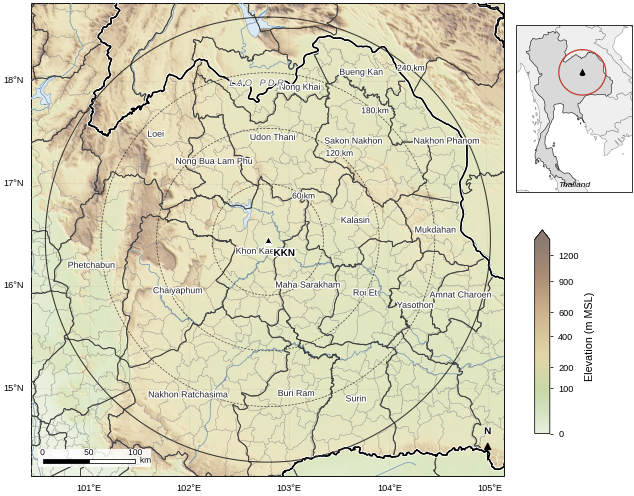

Saved: Fig02_beam_geometry_pcappi.pdf (0.05 MB), Fig02_beam_geometry_pcappi.png (0.14 MB)


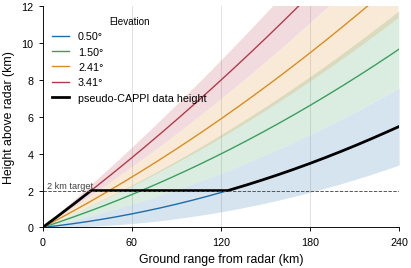

Saved: Fig03_qc_ppi.pdf (1.34 MB), Fig03_qc_ppi.png (1.30 MB)


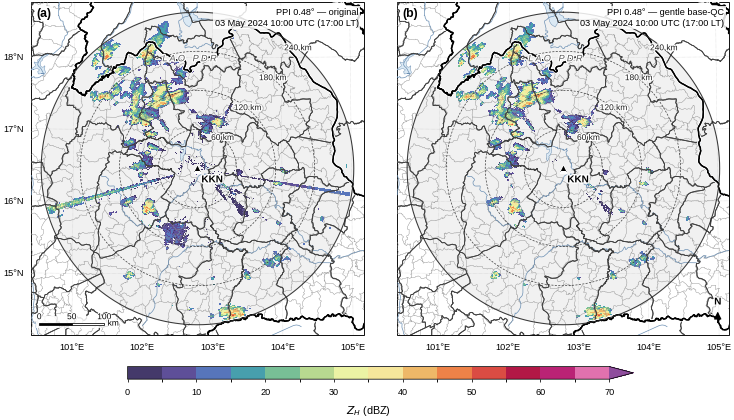

Saved: Fig04_pcappi2km.pdf (1.38 MB), Fig04_pcappi2km.png (1.38 MB)


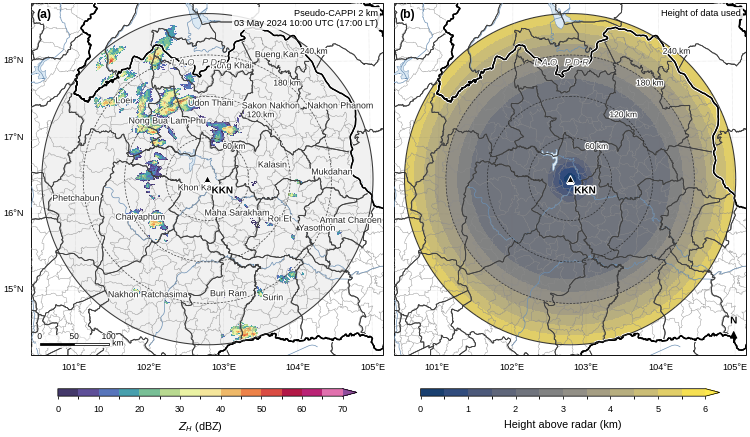

[PosixPath('/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo1_kkn_pysteps/figures/Fig04_pcappi2km.pdf'),
 PosixPath('/content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/2output/Github_Pysteps_Data_prepare/repo1_kkn_pysteps/figures/Fig04_pcappi2km.png')]

In [10]:
LAYERS = prepare_layers(RADAR_INFO["lon"], RADAR_INFO["lat"])
TERRAIN = prepare_terrain(RADAR_INFO["lon"], RADAR_INFO["lat"])

plot_study_area(LAYERS, TERRAIN)
plot_beam_geometry(radar)
plot_qc_ppi(radar, FIELDS, qc, SINGLE_TIME)
plot_pcappi(pc, SINGLE_TIME)

---
# BATCH — ทั้งวัน
## C1. ประมวลผลทุก volume (ข้ามไฟล์ที่ทำแล้ว)

In [11]:
def process_one_volume(raw_file, time_tag):
    out_nc = WORK_DIR / "pcappi" / f"{RADAR_NAME}_{time_tag}_pcappi2km.nc"
    if out_nc.exists() and SKIP_EXISTING:
        return {"time_tag": time_tag, "status": "skipped_existing", "nc": str(out_nc)}
    rdr = read_radar_magic(raw_file, verbose=False)
    flds = detect_fields(rdr)
    q = gentle_base_qc(rdr, flds, verbose=False)
    p = make_pseudo_cappi(rdr, q["reflectivity_qc"])
    info = {"lat": float(rdr.latitude["data"][0]), "lon": float(rdr.longitude["data"][0]),
            "alt": float(rdr.altitude["data"][0])}
    d = make_dataset(p["dbz"][None], [tag_to_datetime(time_tag)], [1], p, info,
                     scan_times=[radar_start_time(rdr)])
    write_pcappi_nc(d, out_nc)
    return {"time_tag": time_tag, "status": "success", "nc": str(out_nc),
            "nsweeps": rdr.nsweeps, "nyquist": get_nyquist(rdr), **q["counts"]}


set_pub_style()
inventory = build_inventory()
todo = inventory[inventory["exists"]]
if MAX_VOLUMES:
    todo = todo.head(MAX_VOLUMES)
inventory.to_csv(DATA_DIR / f"{RADAR_NAME}_{CASE_DATE}_inventory.csv", index=False)
print(f"Processing {len(todo)} volumes; missing slots: {int((~inventory['exists']).sum())}")

status = []
t_start = datetime.datetime.now()
for i, r in enumerate(todo.itertuples(), 1):
    try:
        res = process_one_volume(r.raw_file, r.time_tag)
    except Exception as e:
        res = {"time_tag": r.time_tag, "status": "failed", "error": repr(e)}
        with open(WORK_DIR / "logs" / f"{r.time_tag}_error.log", "w") as f:
            f.write(traceback.format_exc())
    status.append(res)
    print(f"[{i:3d}/{len(todo)}] {r.time_tag} {res['status']}")
status = pd.DataFrame(status)
status.to_csv(WORK_DIR / "logs" / f"{RADAR_NAME}_{CASE_DATE}_batch_status.csv", index=False)
print(status["status"].value_counts().to_string(),
      f"\nelapsed: {(datetime.datetime.now()-t_start).total_seconds()/60:.1f} min")

Processing 92 volumes; missing slots: 4
[  1/92] 20240503_0000 skipped_existing
[  2/92] 20240503_0015 skipped_existing
[  3/92] 20240503_0030 skipped_existing
[  4/92] 20240503_0045 skipped_existing
[  5/92] 20240503_0100 skipped_existing
[  6/92] 20240503_0115 skipped_existing
[  7/92] 20240503_0130 skipped_existing
[  8/92] 20240503_0145 skipped_existing
[  9/92] 20240503_0200 skipped_existing
[ 10/92] 20240503_0215 skipped_existing
[ 11/92] 20240503_0230 skipped_existing
[ 12/92] 20240503_0245 skipped_existing
[ 13/92] 20240503_0300 skipped_existing
[ 14/92] 20240503_0315 skipped_existing
[ 15/92] 20240503_0330 skipped_existing
[ 16/92] 20240503_0345 skipped_existing
[ 17/92] 20240503_0500 skipped_existing
[ 18/92] 20240503_0515 skipped_existing
[ 19/92] 20240503_0530 skipped_existing
[ 20/92] 20240503_0545 skipped_existing
[ 21/92] 20240503_0600 skipped_existing
[ 22/92] 20240503_0615 skipped_existing
[ 23/92] 20240503_0630 skipped_existing
[ 24/92] 20240503_0645 skipped_existing


## C2. รวมเป็นไฟล์รายวัน (แกนเวลาทุก 15 นาที, ช่องที่ไม่มีไฟล์ = NaN)

In [12]:
slots = expected_slots()
files = {}                                    # time_tag -> per-volume NetCDF
for p in sorted((WORK_DIR / "pcappi").glob(f"{RADAR_NAME}_{CASE_DATE}_*_pcappi2km.nc")):
    tag = "_".join(p.stem.split("_")[1:3])
    files[tag] = p

first = xr.open_dataset(next(iter(files.values())))
ny, nx = first.sizes["y"], first.sizes["x"]
stack = np.full((len(slots), ny, nx), np.nan, np.float32)
available = np.zeros(len(slots), np.uint8)
scan_times = [pd.NaT] * len(slots)
cov_any = np.zeros((ny, nx), bool)
for i, dt in enumerate(slots):
    tag = dt.strftime("%Y%m%d_%H%M")
    if tag in files:
        with xr.open_dataset(files[tag]) as d:
            stack[i] = d["reflectivity"].values[0]
            scan_times[i] = d["volume_start_time"].values[0] if "volume_start_time" in d else pd.NaT
            cov_any |= d["coverage_mask"].values.astype(bool)
        available[i] = 1

pc_ref = {"x": first["x"].values, "y": first["y"].values,
          "source_height_m": first["source_height_m"].values, "coverage": cov_any}
info = {"lat": first.attrs["radar_latitude"], "lon": first.attrs["radar_longitude"],
        "alt": first.attrs["radar_altitude_m"]}
first.close()
ds_day = make_dataset(stack, slots, available, pc_ref, info, scan_times=scan_times)
write_pcappi_nc(ds_day, DAILY_NC)
size_mb = DAILY_NC.stat().st_size / 1e6
print(f"Saved {DAILY_NC.name}: {size_mb:.2f} MB | available {available.sum()}/{len(slots)} slots")
if size_mb > 25:
    print("WARNING: > 25 MB (GitHub web-upload limit). Use git push or GitHub Releases.")

stats = pd.DataFrame([{"time_utc": dt, "available": int(available[i]),
                       **(echo_stats(stack[i]) if available[i] else
                          {**{f"area_ge{t}_km2": np.nan for t in AREA_THRESHOLDS_DBZ}, "max_dbz": np.nan})}
                      for i, dt in enumerate(slots)])
stats.to_csv(DATA_DIR / f"{RADAR_NAME}_{CASE_DATE}_echo_stats.csv", index=False)

Saved KKN_20240503_pcappi2km_dbz.nc: 1.59 MB | available 92/96 slots


## C3. ภาพรายวัน: ลำดับเวลาของพายุ, อนุกรมเวลาพื้นที่ echo, ความถี่ echo, animation

Boundaries read from boundaries_KKN_255km.gpkg
Peak time (largest area_ge40_km2 ): 2024-05-03 09:45:00
Sequence panels: ['20240503_0815', '20240503_0845', '20240503_0915', '20240503_0945', '20240503_1015', '20240503_1045']
Saved: Fig05_pcappi_sequence.pdf (3.91 MB), Fig05_pcappi_sequence.png (2.29 MB)


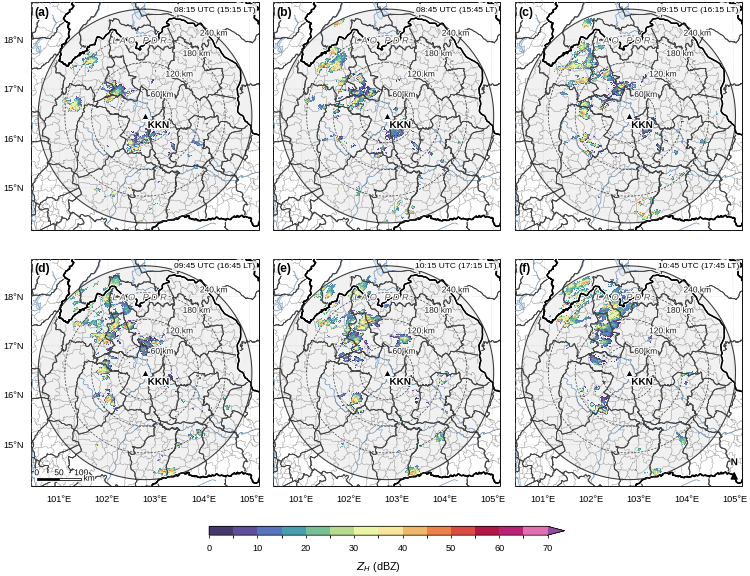

Saved: Fig06_echo_area_timeseries.pdf (0.03 MB), Fig06_echo_area_timeseries.png (0.17 MB)


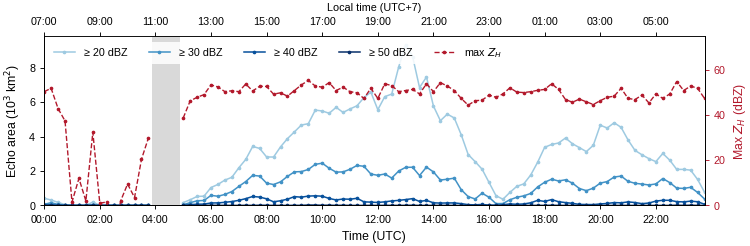

Saved: Fig07_echo_frequency.pdf (0.67 MB), Fig07_echo_frequency.png (0.88 MB)


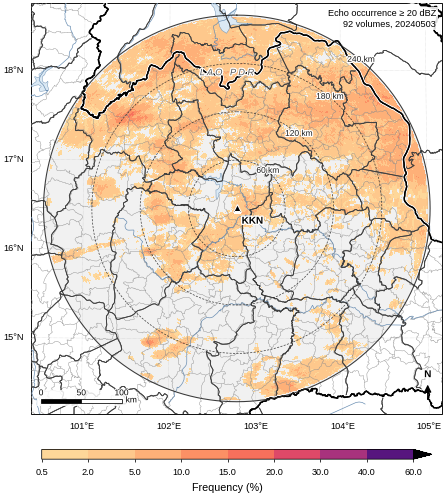

Saved: Anim_pcappi2km.mp4 (2.24 MB)


In [13]:
LAYERS = prepare_layers(info["lon"], info["lat"])
ds_day = xr.open_dataset(DAILY_NC)

key = "area_ge40_km2" if np.nanmax(stats["area_ge40_km2"]) > 0 else "area_ge30_km2"
peak_time = stats.loc[stats[key].idxmax(), "time_utc"]
print("Peak time (largest", key, "):", peak_time)
if SEQUENCE_TIMES:
    seq_tags = SEQUENCE_TIMES
else:
    avail_times = pd.to_datetime(stats.loc[stats["available"] == 1, "time_utc"])
    seq_tags = []
    for off in [-90, -60, -30, 0, 30, 60]:
        target = peak_time + pd.Timedelta(minutes=off)
        tsel = avail_times.iloc[np.argmin(np.abs((avail_times - target).values))]
        tag = tsel.strftime("%Y%m%d_%H%M")
        if tag not in seq_tags:
            seq_tags.append(tag)
print("Sequence panels:", seq_tags)

plot_sequence(ds_day, seq_tags)
plot_timeseries(stats)
plot_echo_frequency(ds_day)
if MAKE_ANIMATION:
    make_animation(ds_day)

## C4. manifest.json และตรวจขนาดไฟล์ก่อนขึ้น GitHub

In [14]:
manifest = {
    "dataset": DAILY_NC.name,
    "processing_code": PREP_VERSION,
    "notebook": "00_prepare_pcappi_for_pysteps.ipynb",
    "created_utc": f"{datetime.datetime.utcnow():%Y-%m-%dT%H:%M:%SZ}",
    "radar": RADAR_NAME, "case_date_utc": CASE_DATE,
    "raw_files_found": int(inventory["exists"].sum()),
    "slots_expected": len(slots),
    "missing_slots": inventory.loc[~inventory["exists"], "time_tag"].tolist(),
    "failed": status.loc[status["status"] == "failed", "time_tag"].tolist() if "status" in status else [],
    "peak_time_utc": str(peak_time),
    "grid": {"projection": aeqd_proj4(info["lon"], info["lat"]), "resolution_m": GRID_RES_M,
             "half_width_km": RANGE_MAX_KM, "shape_yx": [ny, nx]},
    "pcappi_height_m_above_radar": PCAPPI_HEIGHT_M,
    "zerovalue_dbz": ZEROVALUE_DBZ, "threshold_dbz": PCAPPI_MIN_DBZ,
    "qc_thresholds": {k: globals()[k] for k in [
        "ZH_ECHO_FLOOR_DBZ", "NONMET_RHOHV_MAX", "NONMET_ZH_MAX_DBZ", "SPECKLE_MIN_GATES",
        "FLARE_MIN_LEN_KM", "FLARE_ZH_MIN_DBZ", "FLARE_RHOHV_MEAN_MAX", "FLARE_VELVALID_MAX",
        "FLARE_PROTECT_DBZ", "FLARE_PROTECT_FRAC"]},
    "basemap_sources": {"boundaries": "geoBoundaries gbOpen (CC BY 4.0), https://www.geoboundaries.org",
                        "terrain": "AWS Open Data Terrain Tiles (Mapzen); SRTM/GMTED2010/ETOPO1",
                        "water": "Natural Earth (public domain)"},
    "data_credit": "Radar data: Thai Meteorological Department (TMD)",
}
with open(DATA_DIR / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False, default=str)

print("Files in repo folder:")
for p in sorted(REPO_DIR.rglob("*")):
    if p.is_file():
        mb = p.stat().st_size / 1e6
        flag = "  <-- > 25 MB" if mb > 25 else ""
        print(f"  {p.relative_to(REPO_DIR)}  {mb:.2f} MB{flag}")

Files in repo folder:
  data/KKN_20240503/KKN_20240503_echo_stats.csv  0.00 MB
  data/KKN_20240503/KKN_20240503_inventory.csv  0.01 MB
  data/KKN_20240503/KKN_20240503_pcappi2km_dbz.nc  1.59 MB
  data/KKN_20240503/manifest.json  0.00 MB
  data/basemap/boundaries_KKN_255km.gpkg  2.60 MB
  data/basemap/terrain_KKN_aeqd_600m.nc  0.73 MB
  figures/Anim_pcappi2km.mp4  2.24 MB
  figures/Fig01_study_area.pdf  3.14 MB
  figures/Fig01_study_area.png  2.46 MB
  figures/Fig02_beam_geometry_pcappi.pdf  0.05 MB
  figures/Fig02_beam_geometry_pcappi.png  0.14 MB
  figures/Fig03_qc_ppi.pdf  1.34 MB
  figures/Fig03_qc_ppi.png  1.30 MB
  figures/Fig04_pcappi2km.pdf  1.38 MB
  figures/Fig04_pcappi2km.png  1.38 MB
  figures/Fig05_pcappi_sequence.pdf  3.91 MB
  figures/Fig05_pcappi_sequence.png  2.29 MB
  figures/Fig06_echo_area_timeseries.pdf  0.03 MB
  figures/Fig06_echo_area_timeseries.png  0.17 MB
  figures/Fig07_echo_frequency.pdf  0.67 MB
  figures/Fig07_echo_frequency.png  0.88 MB


## C5. (ทางเลือก) ทดสอบว่า pysteps ใช้ข้อมูลได้จริง
แปลง dBZ → mm/h (Marshall–Palmer เป็นค่าเริ่มต้น; ใน repo จะเปรียบเทียบกับ Z–R ฝนเขตร้อน) แล้วคำนวณ motion field ด้วย Lucas–Kanade จาก 3 ภาพรอบช่วงพีค

In [15]:
try:
    import pysteps
except ImportError:
    !pip -q install pysteps
    import pysteps
from pysteps import motion
from pysteps.utils import conversion, transformation

i_peak = int(np.where(pd.to_datetime(ds_day["time"].values) == peak_time)[0][0])
t0, t1 = slots[max(i_peak - 2, 0)], slots[i_peak]
R, meta, ts = load_pcappi_for_pysteps(DAILY_NC, t0, t1)
R = np.where(np.isfinite(R), R, meta["zerovalue"])        # outside coverage -> no rain
RR, meta_rr = conversion.to_rainrate(R, meta)              # dBZ -> mm/h
Rdb, meta_db = transformation.dB_transform(RR, meta_rr, threshold=0.1, zerovalue=-15.0)
V = motion.get_method("LK")(Rdb)
speed = np.hypot(V[0], V[1]) * GRID_RES_M / (SLOT_MINUTES * 60)
from importlib.metadata import version as pkg_version   # pysteps has no __version__
print(f"pysteps {pkg_version('pysteps')}: motion field {V.shape}, "
      f"median speed in echo = {np.nanmedian(speed[RR[-1] > 1]):.1f} m/s")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 686.9/686.9 kB 5.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc

pysteps 1.21.5: motion field (2, 481, 481), median speed in echo = 8.4 m/s
